# Temporal-statistics encoder: approved controlled experiment
Nine new runs: three nearly parameter-matched architectures x seeds 42/43/44. Same frozen training/validation users, Phase-2 transforms, weight, optimizer, epochs and threshold. No test parsing, text/graph additions, learned fusion gates, contrastive loss, pseudo-labeling, or missingness augmentation. Historical baseline files remain frozen.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'configs/temporal_statistics_v1.json').exists())
sys.path.insert(0, str(ROOT))
from src.temporal_statistics import run, verify
from IPython.display import display, Image
print(ROOT)

C:\Users\p.vazifeh\Desktop\University\Project\Bot Detection Implementation


## Fixed comparison
A: flat 40 features + seven temporal masks -> 49 -> 32 -> 1 (4,083 parameters).
B: non-temporal 33 -> 48; temporal seven values + seven masks -> 16; concatenate 64 -> 32 -> 1 (4,081 parameters). The temporal branch has no BatchNorm and is forced to zero when wholly unavailable.
C: remaining 33 -> 59 -> 32 -> 1 (4,077 parameters). This removes the seven designated statistics, not every time-related signal.
ReLU and dropout 0.3; BatchNorm after the first non-temporal/flat linear layer. Full training class ratio 540/131; AdamW lr 0.001, decay 0.0001, batch 32, 50 epochs. Minimum user-mean unweighted validation BCE selects the primary checkpoint; final epoch is secondary. Threshold 0.5.
Primary: B minus A. Secondary: B minus C. Dedicated shuffle generators match actual batch order across architectures; different architectures do not share initial tensors/dropout trajectories. No missing values are estimated and no user is removed.

In [2]:
output_dir, validation_metrics, seed_summary = run(ROOT)
print('OUTPUT_VERSION:', output_dir)
display(validation_metrics)
display(seed_summary)

Training flat_masked, seed 42


flat_masked, seed 42, epoch 25: validation BCE 0.6029


flat_masked, seed 42, epoch 50: validation BCE 0.6388


Training temporal_branch, seed 42


temporal_branch, seed 42, epoch 25: validation BCE 0.6239


...

without_seven_statistics, seed 44, epoch 25: validation BCE 0.5916


without_seven_statistics, seed 44, epoch 50: validation BCE 0.6153


OUTPUT_VERSION: C:\Users\p.vazifeh\Desktop\University\Project\Bot Detection Implementation\results\versions\temporal_statistics_v1\20260921T090006150868Z_61ce9da6


,seed,arm,policy,epoch,n,bots,threshold,bot_precision,bot_recall,bot_f1,...,fp,fn,tp,predicted_bots,roc_auc,average_precision,pos_weight,parameter_count,validation_weighted_loss,validation_unweighted_loss
0,42,flat_masked,best_unweighted_validation_loss,12,144,28,0.5,0.400000,0.714286,0.512821,...,30,8,20,50,0.765394,0.531347,4.122137,4083,0.942962,0.554418
1,42,flat_masked,last,50,144,28,0.5,0.360000,0.642857,0.461538,...,32,10,18,50,0.733682,0.513978,4.122137,4083,1.310612,0.638765
2,42,temporal_branch,best_unweighted_validation_loss,12,144,28,0.5,0.367347,0.642857,0.467532,...,31,10,18,49,0.773399,0.534680,4.122137,4081,0.934310,0.557748
3,42,temporal_branch,last,50,144,28,0.5,0.333333,0.678571,0.447059,...,38,9,19,57,0.714901,0.475800,4.122137,4081,1.319343,0.721112
4,42,without_seven_statistics,best_unweighted_validation_loss,12,144,28,0.5,0.321429,0.642857,0.428571,...,38,10,18,56,0.762931,0.515580,4.122137,4077,0.946665,0.575873
5,42,without_seven_statistics,last,50,144,28,0.5,0.283333,0.607143,0.386364,...,43,11,17,60,0.721367,0.465744,4.122137,4077,1.241095,0.687009
6,43,flat_masked,best_unweighted_validation_loss,28,144,28,0.5,0.340426,0.571429,0.426667,...,31,12,16,47,0.734298,0.548190,4.122137,4083,1.108976,0.560501
7,43,flat_masked,last,50,144,28,0.5,0.347826,0.571429,0.432432,...,30,12,16,46,0.737685,0.515340,4.122137,4083,1.249344,0.575756
8,43,temporal_branch,best_unweighted_validation_loss,21,144,28,0.5,0.365385,0.678571,0.475000,...,33,9,19,52,0.758621,0.557178,4.122137,4081,1.000583,0.538830
9,43,temporal_branch,last,50,144,28,0.5,0.320755,0.607143,0.419753,...,36,11,17,53,0.732451,0.527168,4.122137,4081,1.245663,0.616335


,arm,policy,bot_f1_mean,bot_f1_std,bot_f1_min,bot_f1_max,bot_precision_mean,bot_precision_std,bot_precision_min,bot_precision_max,...,roc_auc_min,roc_auc_max,average_precision_mean,average_precision_std,average_precision_min,average_precision_max,epoch_mean,epoch_std,epoch_min,epoch_max
0,flat_masked,best_unweighted_validation_loss,0.473162,0.043482,0.426667,0.512821,0.374468,0.030686,0.340426,0.400000,...,0.734298,0.766010,0.545706,0.013292,0.531347,0.557580,18.666667,8.326664,12,28
1,flat_masked,last,0.464657,0.033892,0.432432,0.500000,0.364147,0.018742,0.347826,0.384615,...,0.733682,0.746305,0.513782,0.001665,0.512027,0.515340,50.000000,0.000000,50,50
2,temporal_branch,best_unweighted_validation_loss,0.478561,0.013175,0.467532,0.493151,0.377577,0.019443,0.365385,0.400000,...,0.758621,0.773399,0.552904,0.016508,0.534680,0.566855,16.333333,4.509250,12,21
3,temporal_branch,last,0.440836,0.018762,0.419753,0.455696,0.335676,0.016221,0.320755,0.352941,...,0.714901,0.740764,0.518340,0.038885,0.475800,0.552051,50.000000,0.000000,50,50
4,without_seven_statistics,best_unweighted_validation_loss,0.441097,0.013681,0.428571,0.455696,0.335901,0.015912,0.321429,0.352941,...,0.745998,0.762931,0.552138,0.031981,0.515580,0.574938,22.666667,9.237604,12,28
5,without_seven_statistics,last,0.426546,0.043192,0.386364,0.472222,0.334343,0.051523,0.283333,0.386364,...,0.721367,0.752771,0.510579,0.039486,0.465744,0.540173,50.000000,0.000000,50,50


,seed,policy,comparison,role,delta_bot_f1,delta_bot_precision,delta_bot_recall,delta_roc_auc,delta_average_precision
0,42,best_unweighted_validation_loss,temporal_branch_minus_flat_masked,primary,-0.045288,-0.032653,-0.071429,0.008005,0.003333
1,42,best_unweighted_validation_loss,temporal_branch_minus_without_seven_statistics,secondary,0.038961,0.045918,0.000000,0.010468,0.019100
2,42,last,temporal_branch_minus_flat_masked,primary,-0.014480,-0.026667,0.035714,-0.018781,-0.038179
3,42,last,temporal_branch_minus_without_seven_statistics,secondary,0.060695,0.050000,0.071429,-0.006466,0.010056
4,43,best_unweighted_validation_loss,temporal_branch_minus_flat_masked,primary,0.048333,0.024959,0.107143,0.024323,0.008987
5,43,best_unweighted_validation_loss,temporal_branch_minus_without_seven_statistics,secondary,0.019304,0.012443,0.035714,0.002155,-0.017761
6,43,last,temporal_branch_minus_flat_masked,primary,-0.012679,-0.027071,0.035714,-0.005234,0.011828
7,43,last,temporal_branch_minus_without_seven_statistics,secondary,-0.052469,-0.065609,0.000000,-0.020320,0.001348
8,44,best_unweighted_validation_loss,temporal_branch_minus_flat_masked,primary,0.013151,0.017021,0.000000,0.005542,0.009275
9,44,best_unweighted_validation_loss,temporal_branch_minus_without_seven_statistics,secondary,0.054126,0.066667,0.000000,0.025554,0.000960


,split,users,temporal_available,temporal_complete
0,train,671,671,671
1,validation,144,144,144


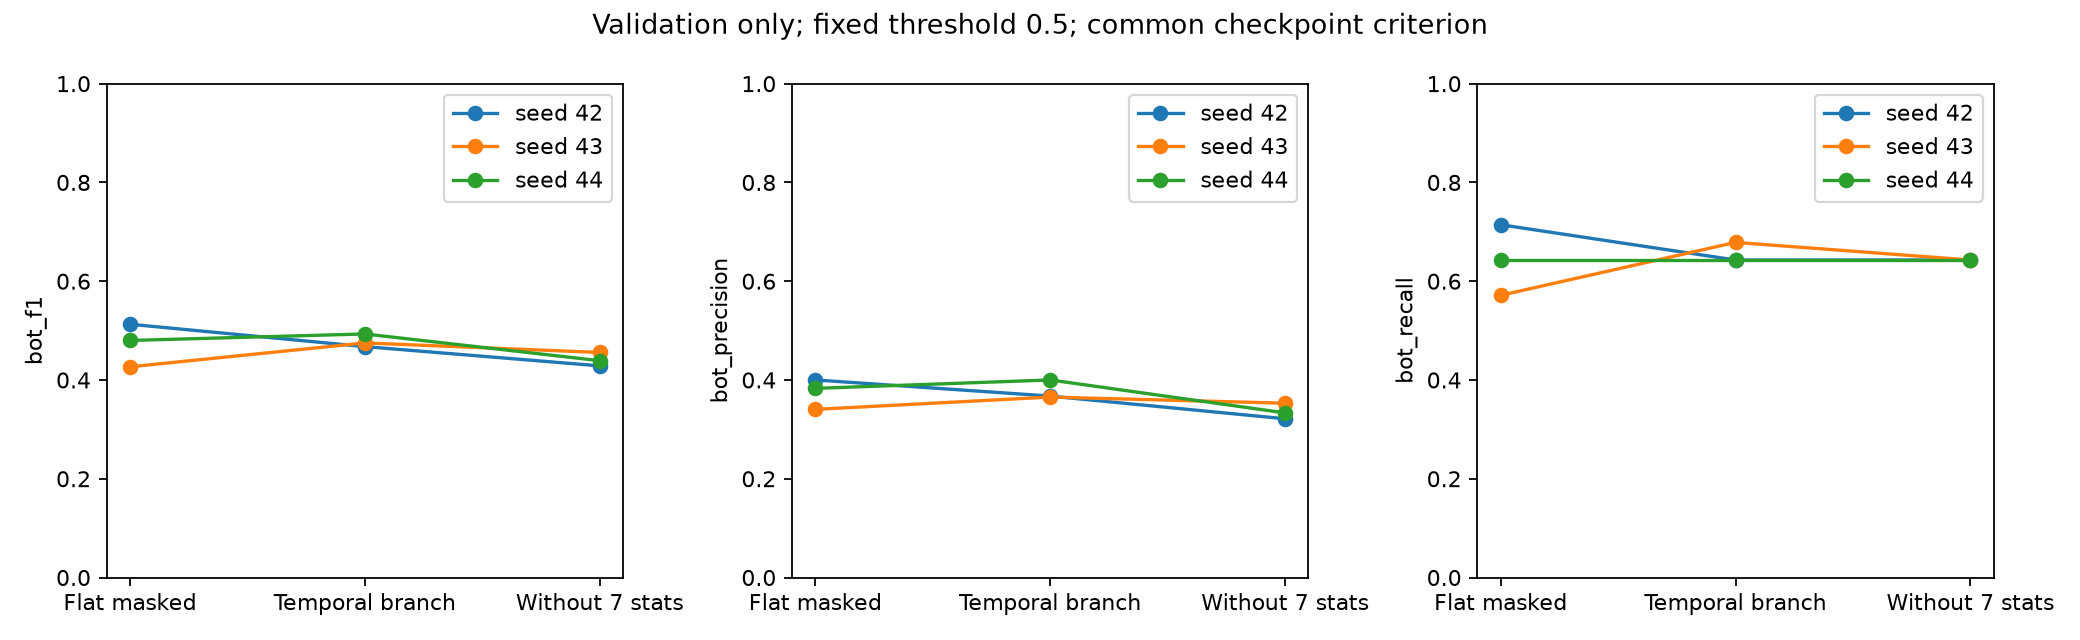

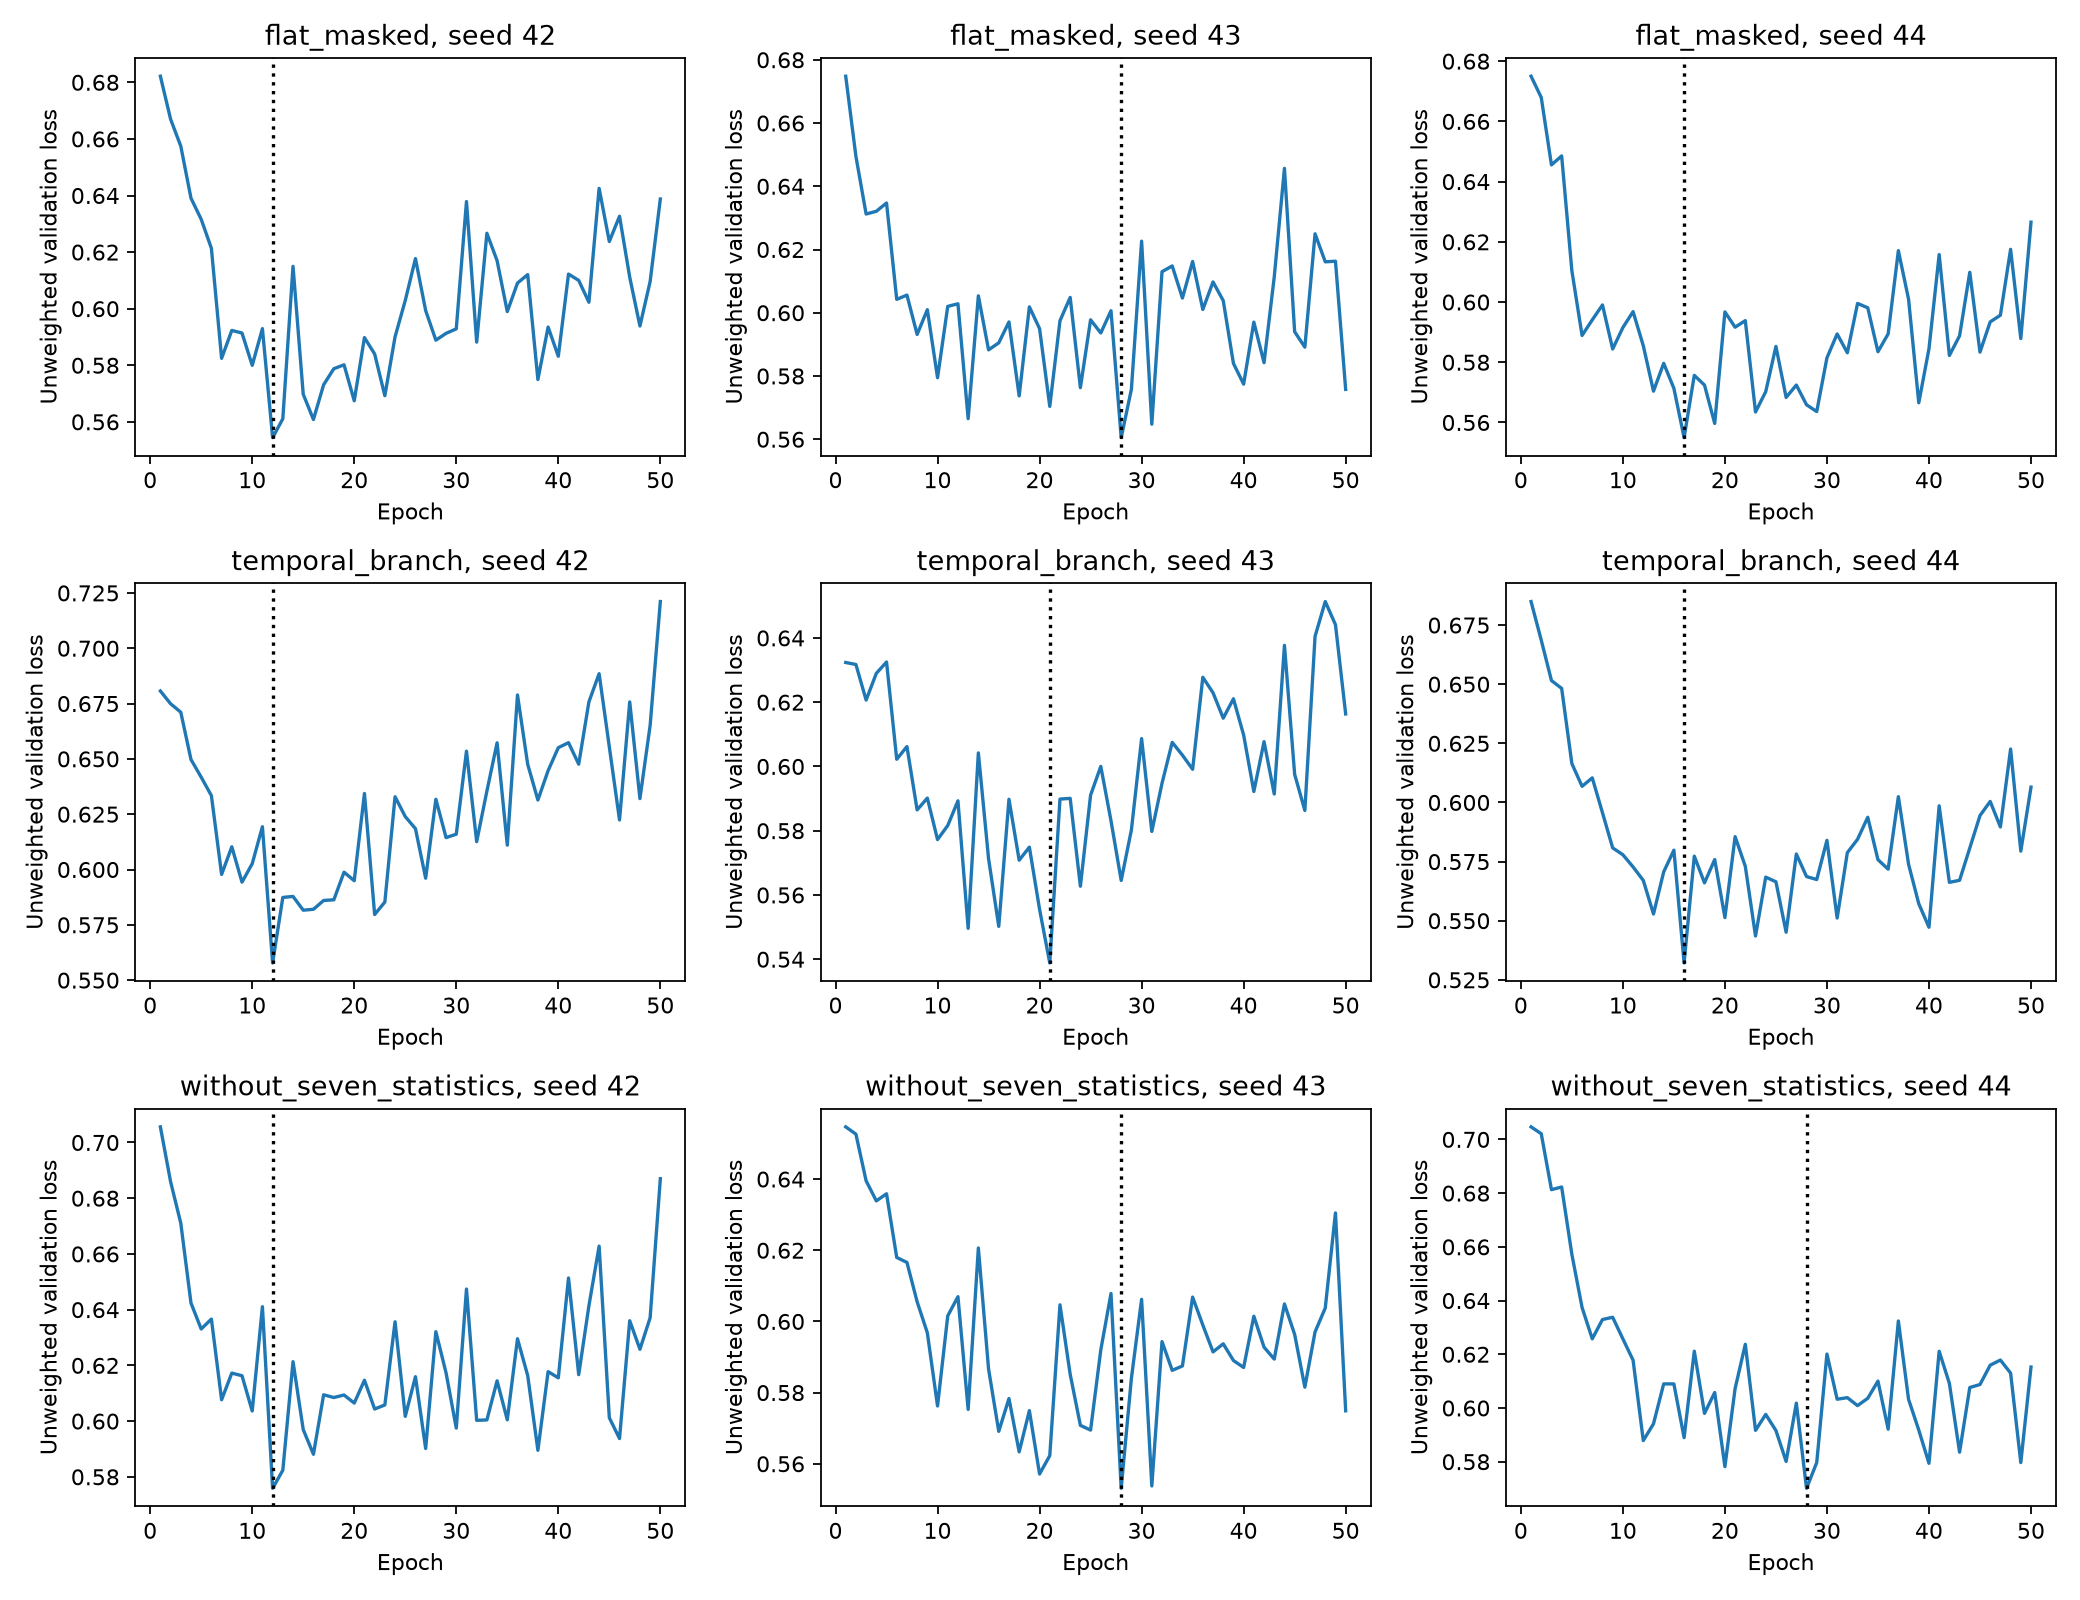

In [3]:
import pandas as pd
display(pd.read_csv(output_dir / 'paired_effects.csv'))
display(pd.read_csv(output_dir / 'temporal_coverage.csv'))
for path in sorted((output_dir / 'figures').glob('*.png')):
    display(Image(filename=str(path)))

In [4]:
verification = verify(ROOT, output_dir)
print(verification)

{'training_runs': 9, 'checkpoints_reloaded': 18, 'validation_prediction_files': 18, 'test_inputs_parsed': 0, 'protected_files_at_execution': 655}


## Interpretation
All train/validation users currently have seven observed temporal statistics; this does not establish complete timelines or verified upstream measurement windows. Functional missingness tests cannot establish naturally missing-modality performance. This is an MLP over statistics, not a temporal Transformer.
Validation selects and evaluates checkpoints: these are development results, not unbiased test estimates. Three seed standard deviations are not confidence intervals. A versus B tests the full branch design, not an isolated causal effect of temporal behavior. B versus C changes information and architecture. Keep secondary checkpoint results separate; no automatic promotion.